### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Homework 7
### Due: Wednesday, Nov. 18 at 11.59pm CT
---

## Problem 1

This is a regression problem. Many of the parts require minor variations of code to switch to new techniques, but otherwise using a similar workflow. 

Note of warning: the data I have provided have associated uncertainties, `yerr`. `sklearn` and `astroML` have different formats for using uncertainties; in `sklearn` fitting you can provide `sample_weight=1/yerr**2`, while in `astroML` fitting you can directly provide `y_error=yerr`.

1. Read in `hw7_data_1.npy`. The dataset should consist of $500$ samples. The first two columns are the two data features, `X`. The third column is the target labels, `y`, and the final column are the heteroscedastic uncertainties on the labels, `yerr`. Make a 2-panel scatter plot of the labels versus each feature.


2. Use multivariate linear regression on this data with its uncertainties (`astroML` rather than plain `sklearn` is the better option here). Print the best-fit intercept and slopes for the features. Make a prediction `Xgrid` over $50$ values from the min to the max value of each feature, and plot the best-fit model on a duplicate of the $2$-panel plot from (1); does this look like a good description of the data?


3. Make a new two-dimensional prediction meshgrid `Xgrid` over the $2$-D feature space, use your best-fit model to predict the labels, and make a $3$-D interactive plot showing the data and your best-fit over the entire space. You may find the following code useful.

In [1]:
# install the relevant interactive plot packages
# only do this once
!pip install ipywidgets ipympl

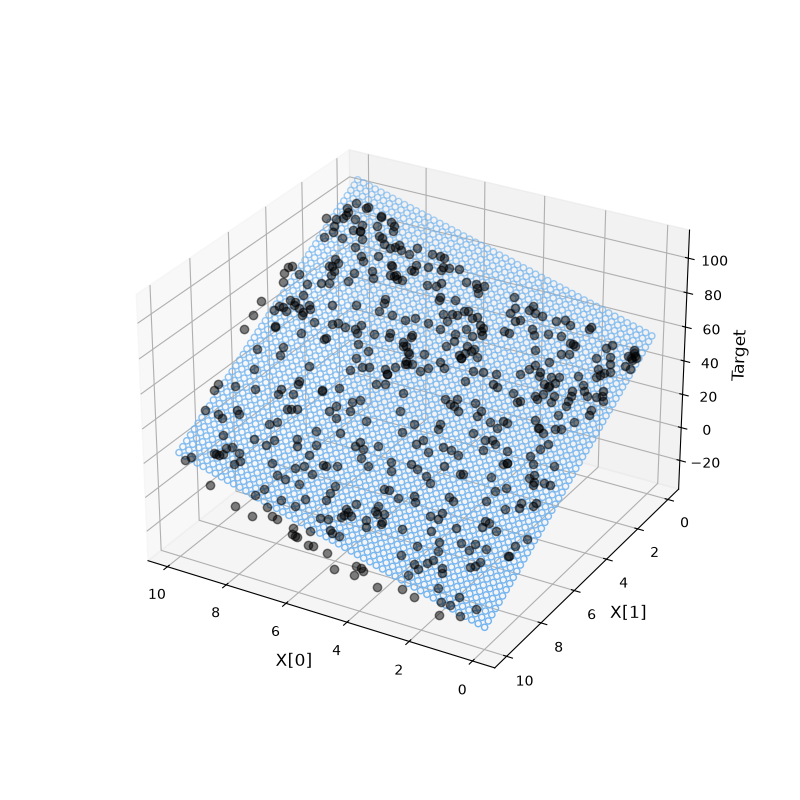

In [11]:
# Makes the plot interactive. 
# You can pan the image.

### always do this line at the start 
### of an interactive plotting cell
%matplotlib widget 
fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:, 0], X[:,1], y, color='k', 
        zorder=15, linestyle='none', 
        marker='o', alpha=0.5)
ax.scatter(x0_mesh.flatten(), x1_mesh.flatten(), y_pred_2d.flatten(), 
           facecolor=(0,0,0,0), s=20, 
           edgecolor='#70b3f0')
ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)
plt.show()

In [2]:
### Always do this line at the start
### of a static plotting cell
%matplotlib inline

4. Sticking with a linear model, now attempt a `GridSearchCV` procedure on the data to find the best `Ridge` regression hyper-parameters. Use the following `param_grid`:
```
ridge_params = {'alpha': [0.05,0.1,0.2,0.5,1.0], 'solver': ['svd', 'lsqr']}
```
What are the `best_params_` and the `best_score_` from this? Fit the data with the best options, and visualize interactively. Try `RidgeCV` also; what cross-validated `alpha_` does it return, and does this agree with `GridSeachCV`? *(Hint: remember to revert to inline matplotlib when you're done each time you make an interactive plot.)*


5. Now model the data using Gaussian process regression and the default kernel. Check what the fit looks like with and with and without uncertainties accounted for. *(Hint: GPR in `sklearn` takes an `alpha` parameter equal to `(yerr/y)**2`.)*


6. Let's look finally at polynomial fitting. Fit a $4$th degree polynomial to the data. Print the best-fit regression coefficients, predict on the 2D meshgrid, and visualize interactively as before. How does this look compared to the linear model and GPR models?


7. Sticking with polynomial fitting, let's find the optimal hyper-parameters through cross-validation. 
- Using `sklearn.model_selection.train_test_split`, first do a train-test split with a `test_size` of $20\%$. Then split out $20\%$ of the training set itself as a cross-validation set (leaving a somewhat smaller set to use for training). Note that you'll need to simultaneously split out `yerr` as well by just providing this as another array to `train_test_split`.
- Compute the training and cross-validation rms errors (and from those, the BIC values) as a function of polynomial degree from $1$ to $10$ inclusive. Plot the rms errors and BIC values as a function of the polynomial degree. 
- Choose the optimal polynomial degree, and train on all training data from the first `train_test_split` operation. Predict the labels of the held-out test set, and finally compute the testing rms error.

Dataset shape: (500, 4)


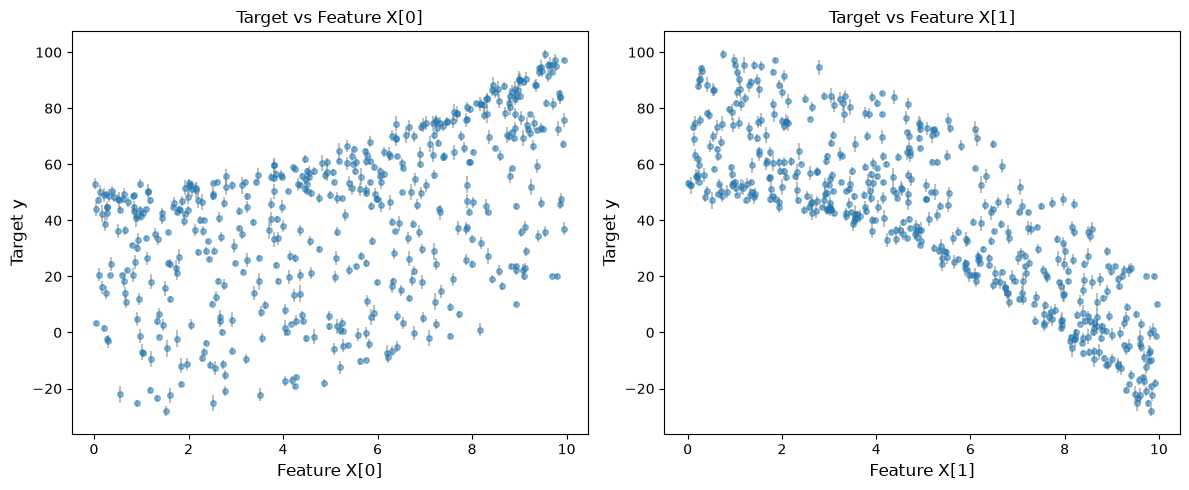

In [3]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("C:/Users/aaron/Git/repos/astrostats_ttu_fall26/coursework/student_folders/aaron_hawley/homeworks/hw_data/hw7_data_1.npy")
X = data[:,:2]
y = data[:,2]
yerr = data[:,3]

print(f"Dataset shape: {data.shape}")

fig, axes = plt.subplots(1, 2, figsize=(12,5))
for i in range(2):
    axes[i].errorbar(X[:, i], y, yerr=yerr, fmt='o', alpha=0.5, markersize=4, ecolor='gray')
    axes[i].set_xlabel(f'Feature X[{i}]', fontsize=12)
    axes[i].set_ylabel('Target y', fontsize=12)
    axes[i].set_title(f'Target vs Feature X[{i}]')

plt.tight_layout()
plt.show()

Best-fit intercept & slopes: [57.10102323  4.94873016 -8.30023407]


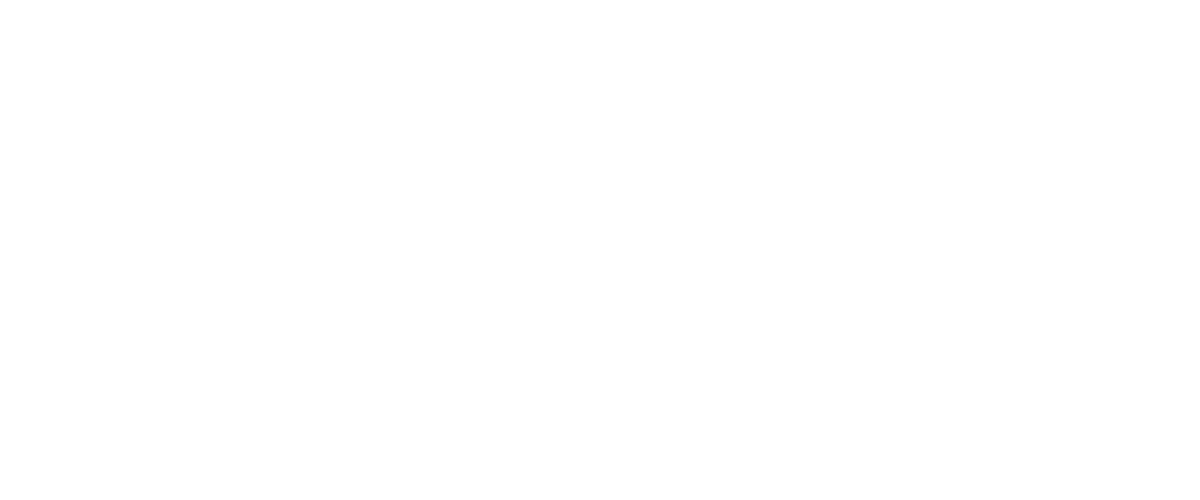

In [7]:
from astroML.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y, y_error=yerr)

print("Best-fit intercept & slopes:", lin_reg.coef_)

Xgrid = np.column_stack([
    np.linspace(X[:, 0].min(), X[:, 0].max(), 50),
    np.linspace(X[:, 1].min(), X[:, 1].max(), 50)
])
y_pred_grid = lin_reg.predict(Xgrid)

fig, axes = plt.subplots(1, 2, figsize=(12,5))
for i in range(2):
    axes[i].errorbar(X[:, i], y, yerr=yerr, fmt='o', alpha=0.5, markersize=4, ecolor='gray', label='Data')
    axes[i].plot(Xgrid[:, 1], y_pred_grid, c='red', lw=2, label='Linear Fit')
    axes[i].set_xlabel(f'Feature X[{i}]', fontsize=12)
    axes[i].set_ylabel('Target y', fontsize=12)
    axes[i].legend()

plt.tight_layout()
plt.show()

In [8]:
x0_mesh, x1_mesh = np.meshgrid(
    np.linspace(X[:, 0].min(), X[:, 0].max(), 50),
    np.linspace(X[:, 1].min(), X[:, 1].max(), 50)
)
Xgrid_2d = np.column_stack([x0_mesh.ravel(), x1_mesh.ravel()])
y_pred_2d = lin_reg.predict(Xgrid_2d).reshape(x0_mesh.shape)

C:\Users\aaron\Anaconda3\envs\astr3300\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\aaron\Anaconda3\envs\astr3300\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


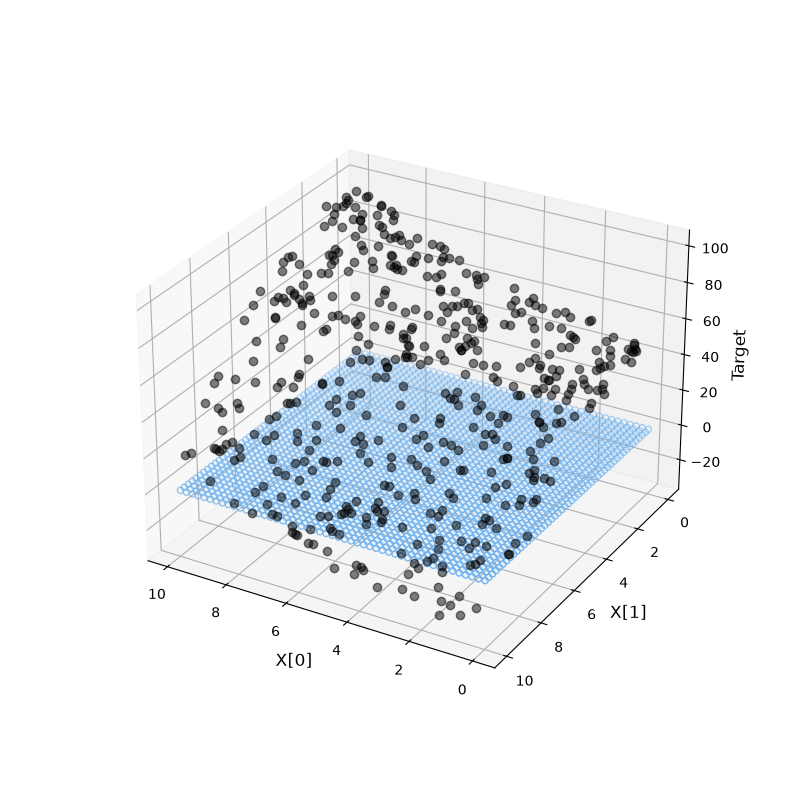

In [14]:
from sklearn.gaussian_process import GaussianProcessRegressor

gpr_no_err = GaussianProcessRegressor(random_state=42)
gpr_no_err.fit(X, y)
y_pred_gpr_no_err = gpr_no_err.predict(Xgrid_2d).reshape(x0_mesh.shape)

gpr_err = GaussianProcessRegressor(random_state=42)
gpr_err.fit(X,y)
y_pred_gpr_err = gpr_err.predict(Xgrid_2d).reshape(x0_mesh.shape)

%matplotlib widget
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(X[:, 0], X[:, 1], y, color='k', zorder=15, linestyle='none', marker='o', alpha=0.5)
ax.scatter(x0_mesh.flatten(), x1_mesh.flatten(), y_pred_gpr_err.flatten(),
           facecolor=(0, 0, 0, 0), s=20, edgecolor='#70b3f0')
ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)
ax.view_init(elev=28, azim=120)
plt.show()

4th-degree polynomial coefficients: [ 1.51971050e-28  5.54313398e-01 -2.07866484e-01  2.86536907e-01
  2.93842379e-03 -7.82230112e-01  2.47603263e-02  2.45748271e-02
 -2.22233559e-02  9.68417971e-03 -9.95958746e-04 -1.12284370e-03
 -1.14462222e-03  2.10142159e-03 -1.08539159e-03]


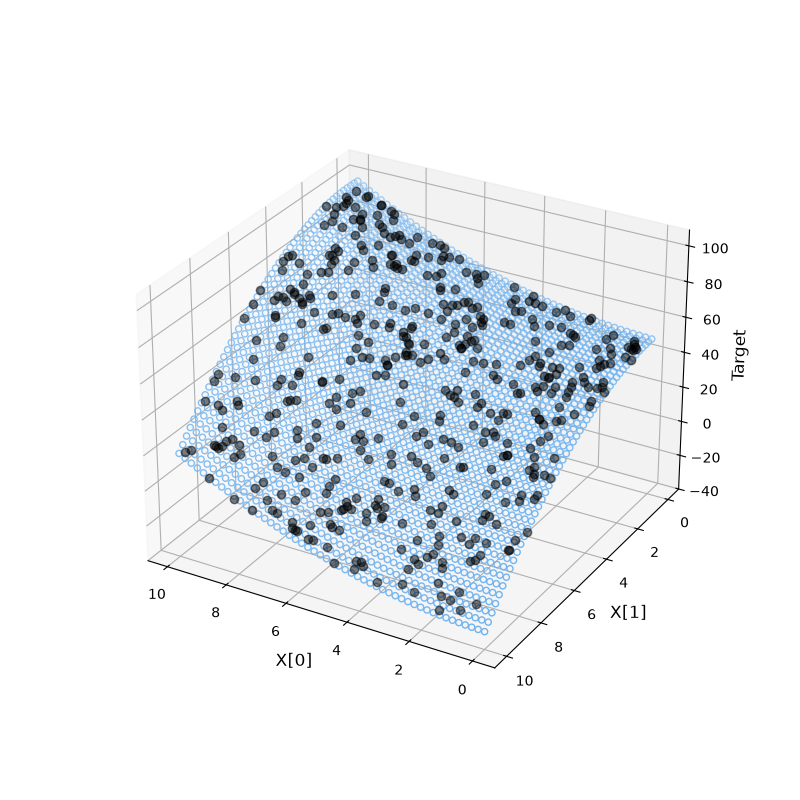

In [15]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression as SklearnLR
from sklearn.pipeline import make_pipeline

poly4 = make_pipeline(PolynomialFeatures(degree=4), SklearnLR())
poly4.fit(X, y, linearregression__sample_weight=1.0 / (yerr**2))

print("4th-degree polynomial coefficients:", poly4.named_steps['linearregression'].coef_)

y_pred_poly4 = poly4.predict(Xgrid_2d).reshape(x0_mesh.shape)

%matplotlib widget
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(X[:, 0], X[:, 1], y, color='k', zorder=15, linestyle='none', marker='o', alpha=0.5)
ax.scatter(x0_mesh.flatten(), x1_mesh.flatten(), y_pred_poly4.flatten(),
           facecolor=(0, 0, 0, 0), s=20, edgecolor='#70b3f0')
ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)
ax.view_init(elev=28, azim=120)
plt.show()

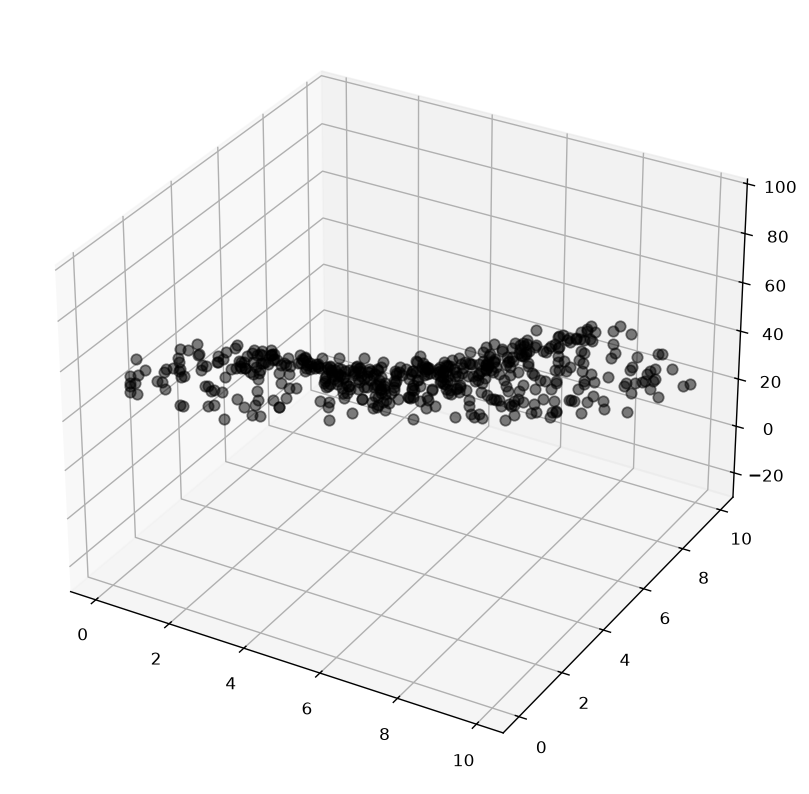

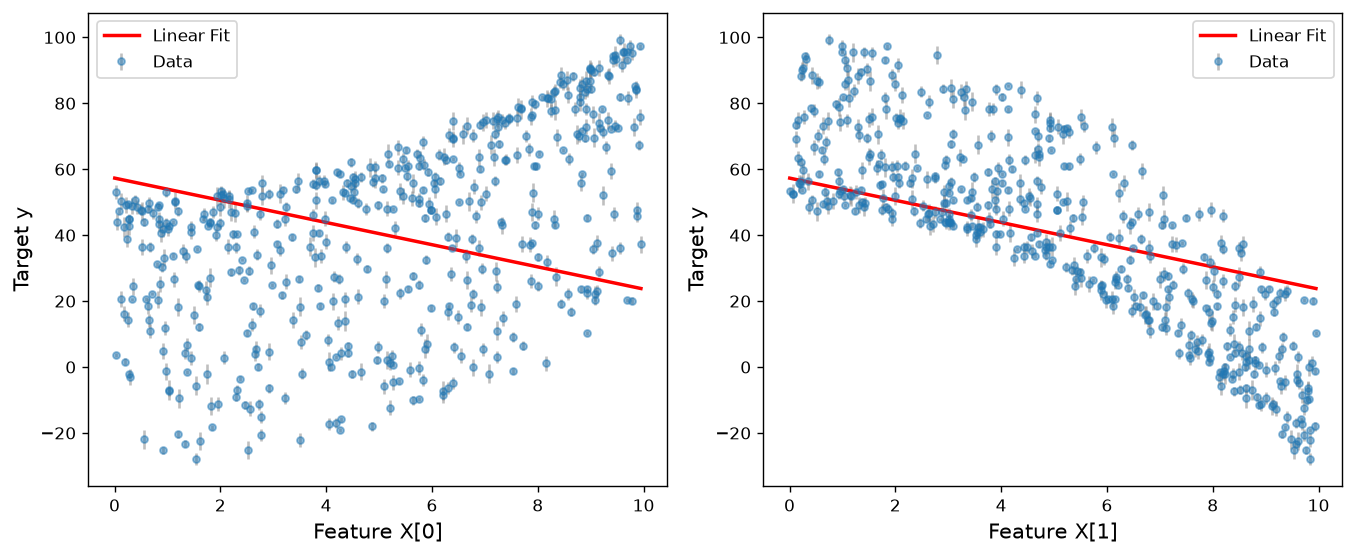

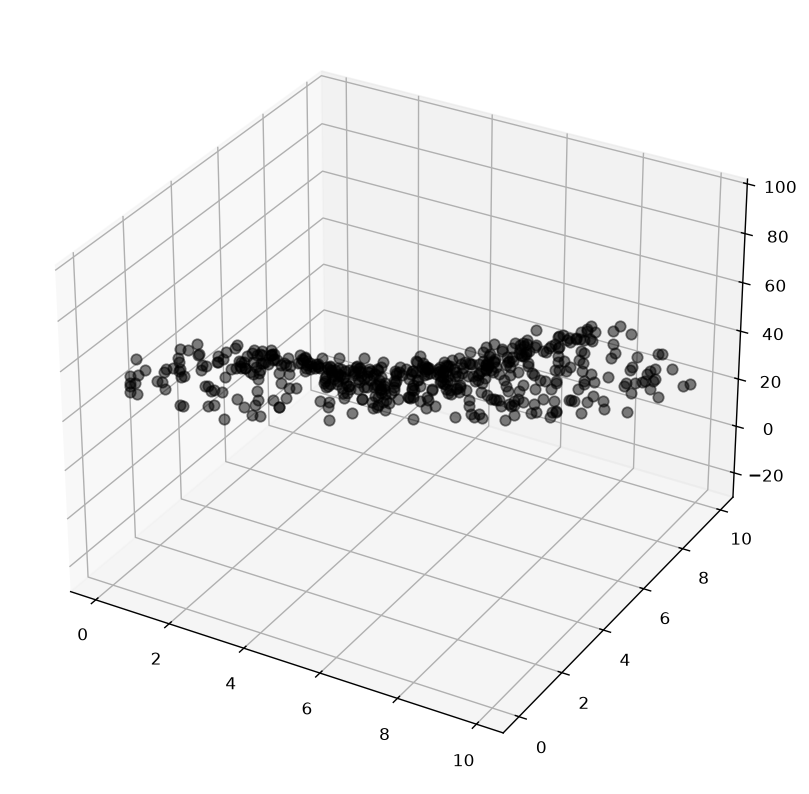

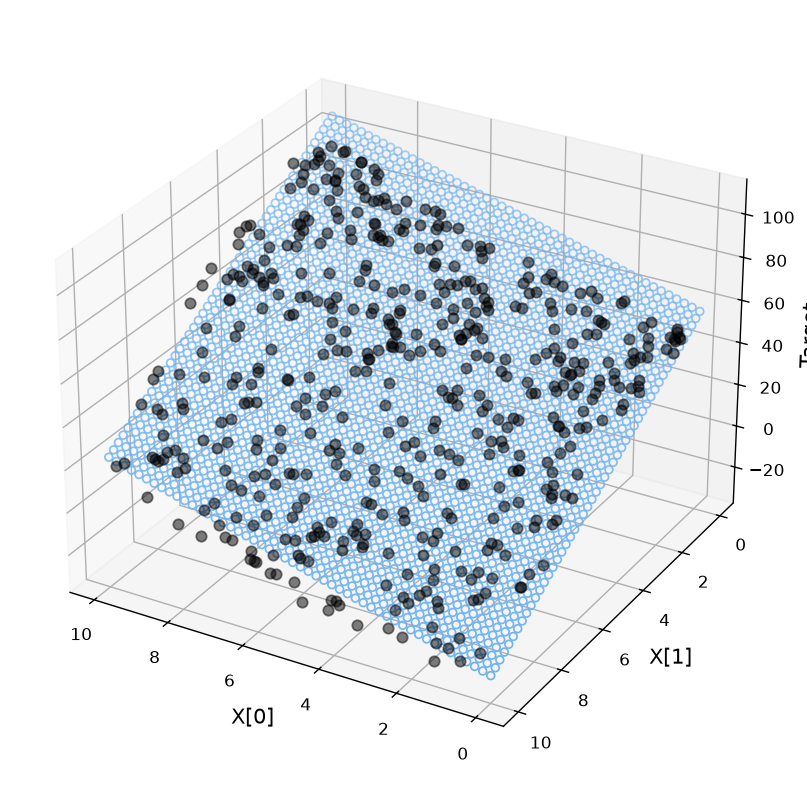

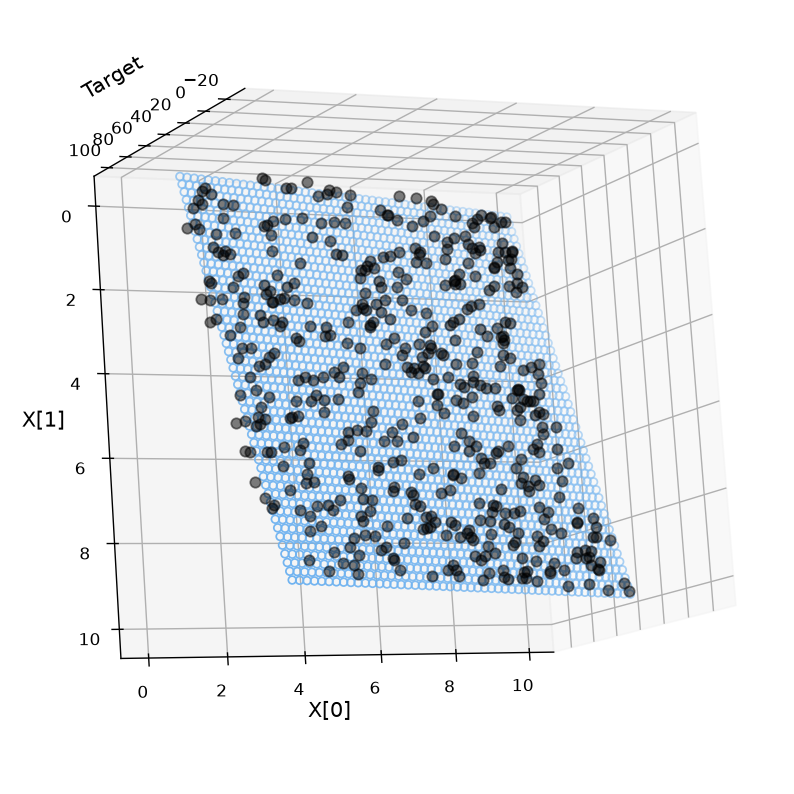

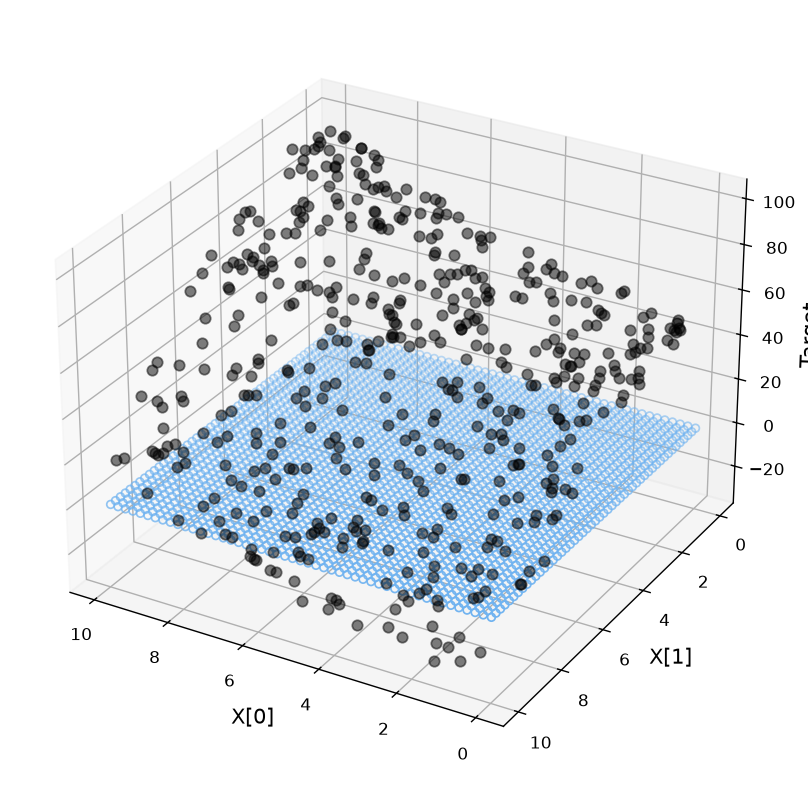

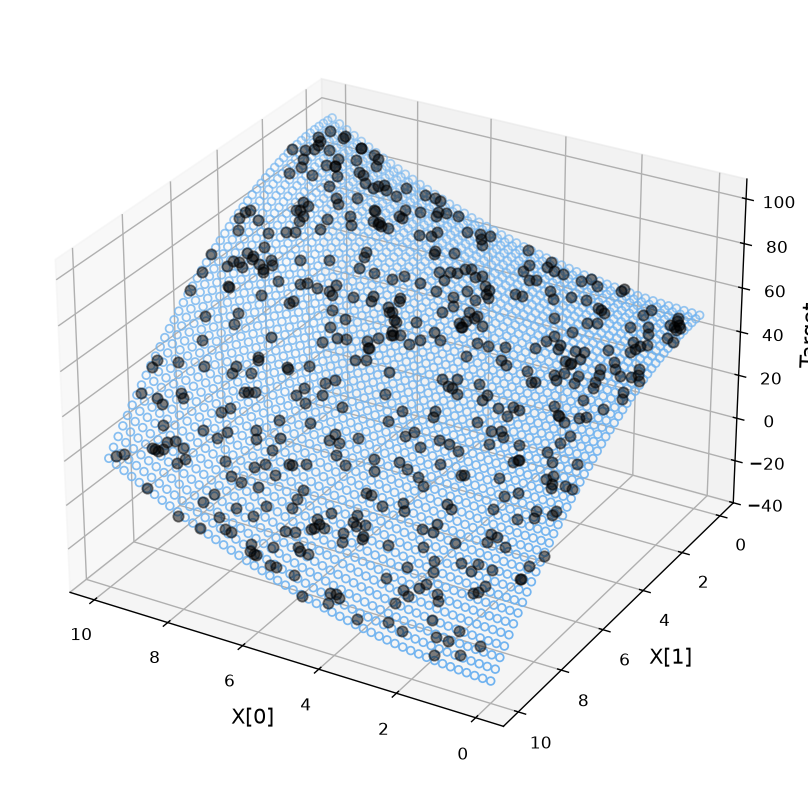

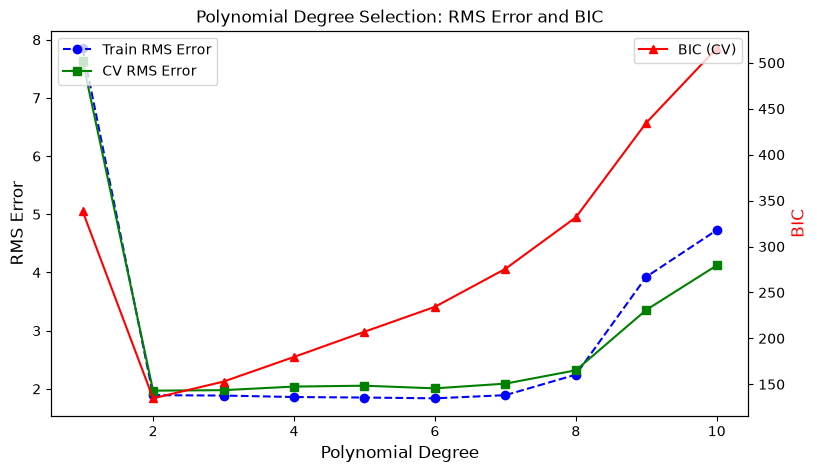

Optimal Polynomial Degree: 2
Held-out Test RMS Error (degree 2): 1.9492


In [16]:
%matplotlib inline
from sklearn.model_selection import train_test_split

# First split: 80% train_full, 20% test
X_train_full, X_test, y_train_full, y_test, yerr_train_full, yerr_test = train_test_split(
    X, y, yerr, test_size=0.20, random_state=42
)

# Second split: 80% train, 20% cross-validation
X_train, X_cv, y_train, y_cv, yerr_train, yerr_cv = train_test_split(
    X_train_full, y_train_full, yerr_train_full, test_size=0.20, random_state=42
)

degrees = np.arange(1, 11)
train_rms, cv_rms, bic_vals = [], [], []
N_cv = len(y_cv)

for d in degrees:
    model = make_pipeline(PolynomialFeatures(degree=d), SklearnLR())
    model.fit(X_train, y_train, linearregression__sample_weight=1.0 / (yerr_train**2))
    
    pred_train = model.predict(X_train)
    pred_cv = model.predict(X_cv)
    
    rms_t = np.sqrt(np.mean((y_train - pred_train)**2))
    rms_c = np.sqrt(np.mean((y_cv - pred_cv)**2))
    
    train_rms.append(rms_t)
    cv_rms.append(rms_c)

    k = model.named_steps['polynomialfeatures'].n_output_features_
    bic = N_cv * np.log(rms_c**2) + k * np.log(N_cv)
    bic_vals.append(bic)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(degrees, train_rms, 'o--', label='Train RMS Error', color='blue')
ax1.plot(degrees, cv_rms, 's-', label='CV RMS Error', color='green')
ax1.set_xlabel('Polynomial Degree', fontsize=12)
ax1.set_ylabel('RMS Error', fontsize=12)
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(degrees, bic_vals, '^-', label='BIC (CV)', color='red')
ax2.set_ylabel('BIC', fontsize=12, color='red')
ax2.legend(loc='upper right')
plt.title('Polynomial Degree Selection: RMS Error and BIC')
plt.show()

best_deg = degrees[np.argmin(cv_rms)]
print(f"Optimal Polynomial Degree: {best_deg}")

best_poly = make_pipeline(PolynomialFeatures(degree=best_deg), SklearnLR())
best_poly.fit(X_train_full, y_train_full, linearregression__sample_weight=1.0 / (yerr_train_full**2))

y_test_pred = best_poly.predict(X_test)
test_rms = np.sqrt(np.mean((y_test - y_test_pred)**2))
print(f"Held-out Test RMS Error (degree {best_deg}): {test_rms:.4f}")

## Problem 2


1. Use the following code snippet to read in SDSS galaxy color data.
<!--```
from astroML.datasets import fetch_sdss_galaxy_colors
data = fetch_sdss_galaxy_colors()
```-->

`data = np.load('../hw_data/hw7_data_2.npy')`

This is a structured numpy array. Find and print all of the column names. Using the data, create arrays of $(u-g)$, $(g-r)$, $(r-i)$, and $(i-z)$ colors. Also create arrays of redshift and the spectral class. How many regular galaxies and how many quasars are in this sample?


2. Make a scatter plot of $(u-g)$ versus $(g-r)$, color coding by galaxy or quasar class. The plot should include appropriate axis labels and a legend. Set `xlim` between -0.5 and 2.5, and `ylim` between -0.5 and 1.5.


3. Stack all colors and the redshift into a data matrix, $X$. Create a target label array that has $0$ for a regular galaxy and $1$ for a quasar. Perform a train-test split, taking $20\%$ of the data for testing.


4. Create a compact `for` loop that iterates over the fitting of a Gaussian Naive Bayes classification algorithm to successively more features of the data. Within the loop, compute and plot an ROC curve. The end result should be a plot showing ROC curves for GNB classification with more and more features of the data, with appropriate axis labels and a legend. Use `xlim` between 0 and 0.01. Which feature seems to make the classification trivially easy? *Note: `predict_proba` returns an array with as many columns as classes. You've labeled quasars as $1$, so for the ROC curve you must make sure to access the relevant quasar probability-- you can find this by accessing the **classes_** attribute of the estimator.*


5. Repeat (4) for Quadratic Discriminant Analysis. 


6. Let's try classification with GMM Bayes. Restrict the training and testing to be just on the $4$ colors. Iterate now over number of components in the GMM Bayes fit up to $10$, plotting ROC curves for all, and find the number of components that gives the best performance.


7. Repeat (6) for $K$-nearest neighbor classification, looping over number of neighbors between 5 and 100 in steps of 10. Find the number that gives the best performance. 


8. Repeat (6) for Decision Tree classification, looping over the maximum tree depth between 1 and 10. Find the number that gives the best performance. 


9. Finally, plot the ROC curves for GNB, QDA, and the best-performing GMMBayes, KNN, and DT classification algorithms, all using just the 4 colors. What is the overall best-performing classifier? 


10. Make a 2-panel plot, showing in the left panel the color-coded training data in $(u-g)$ versus $(g-r)$ (similar to item 2 above), and in the right panel the same features of the testing data color coded by their predicted class from the tuned best-performing classifier. 

In [19]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("C:/Users/aaron/Git/repos/astrostats_ttu_fall26/coursework/student_folders/aaron_hawley/homeworks/hw_data/hw7_data_2.npy")
print("Column names:", data.dtype.names)

u_g = data['u'] - data['g']
g_r = data['g'] - data['r']
r_i = data['r'] - data['i']
i_z = data['i'] - data['z']
redshift = data['redshift']
spec_class = data['specClass'] 

unique_classes, counts = np.unique(spec_class, return_counts=True)
for cls, cnt in zip(unique_classes, counts):
    print(f"Class {cls}: {cnt}")

Column names: ('u', 'g', 'r', 'i', 'z', 'specClass', 'redshift', 'redshift_err')
Class GALAXY: 42808
Class QSO: 7192


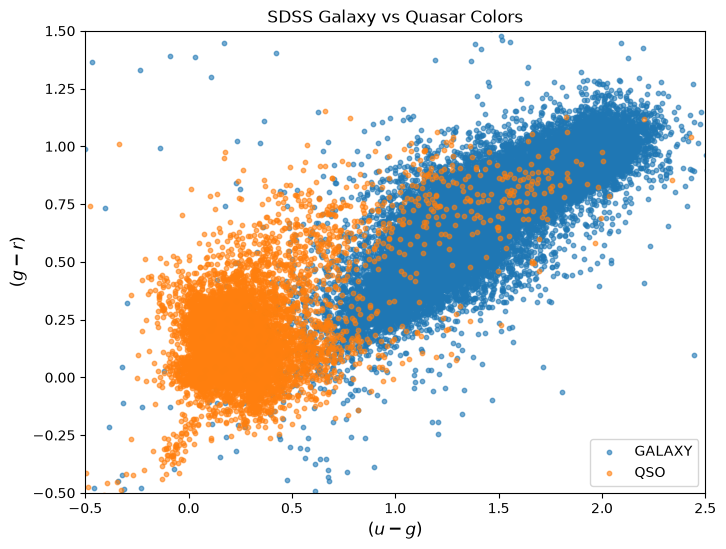

In [20]:
plt.figure(figsize=(8, 6))
for cls in unique_classes:
    mask = (spec_class == cls)
    plt.scatter(u_g[mask], g_r[mask], s=10, alpha=0.6, label=str(cls))

plt.xlim(-0.5, 2.5)
plt.ylim(-0.5, 1.5)
plt.xlabel('$(u - g)$', fontsize=12)
plt.ylabel('$(g - r)$', fontsize=12)
plt.legend()
plt.title('SDSS Galaxy vs Quasar Colors')
plt.show()

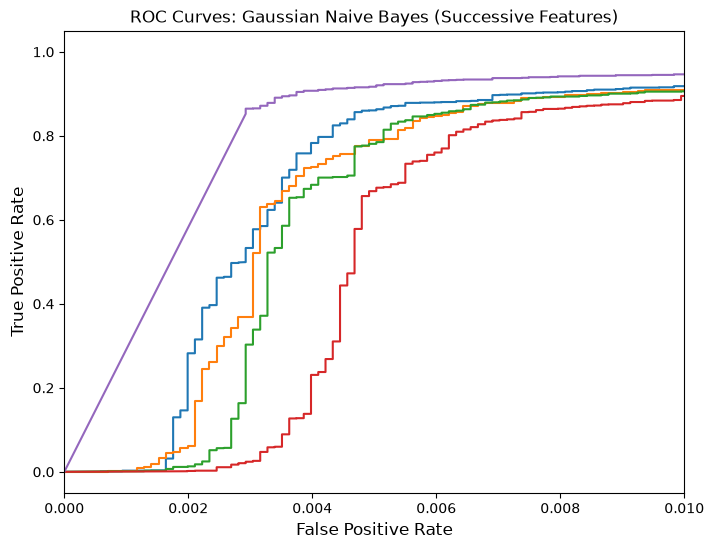

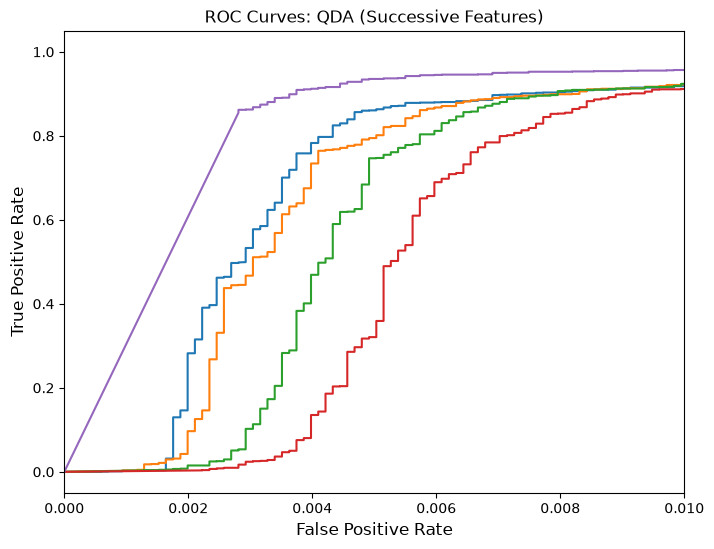

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import roc_curve, auc

X = np.column_stack([u_g, g_r, r_i, i_z, redshift])
feature_names = ['u-g', 'g-r', 'r-i', 'i-z', 'redshift']

y = np.array([1 if 'QSO' in str(c) else 0 for c in spec_class])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

def plot_successive_features_roc(clf, title):
    plt.figure(figsize=(8, 6))
    for i in range(1, X.shape[1] + 1):
        clf.fit(X_train[:, :i], y_train)
        qso_idx = np.where(clf.classes_ == 1)[0][0]
        y_prob = clf.predict_proba(X_test[:, :i])[:, qso_idx]
        
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"Features 1..{i} ({', '.join(feature_names[:i])}) | AUC={roc_auc:.4f}")
        
    plt.xlim(0, 0.01)
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(title)
    plt.show()

plot_successive_features_roc(GaussianNB(), 'ROC Curves: Gaussian Naive Bayes (Successive Features)')
plot_successive_features_roc(QuadraticDiscriminantAnalysis(), 'ROC Curves: QDA (Successive Features)')

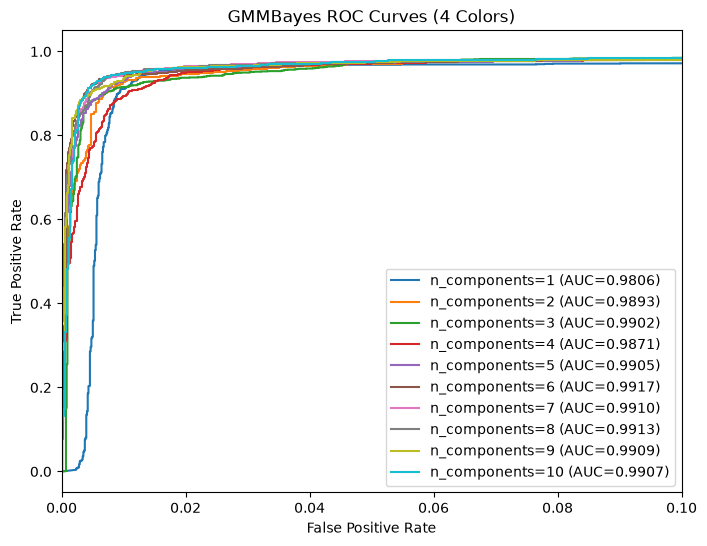

Best GMMBayes n_components: 6 (AUC = 0.9917)


In [29]:
from astroML.classification import GMMBayes
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

X_train_col = X_train[:, :4]
X_test_col = X_test[:, :4]

plt.figure(figsize=(8, 6))
best_gmm_auc, best_gmm_comp = 0, 1
for n_comp in range(1, 11):
    gmm = GMMBayes(n_components=n_comp)
    gmm.fit(X_train_col, y_train)
    qso_idx = np.where(gmm.classes_ == 1)[0][0]
    y_prob = gmm.predict_proba(X_test_col)[:, qso_idx]
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'n_components={n_comp} (AUC={roc_auc:.4f})')
    if roc_auc > best_gmm_auc:
        best_gmm_auc, best_gmm_comp = roc_auc, n_comp

plt.xlim(0, 0.1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('GMMBayes ROC Curves (4 Colors)')
plt.legend()
plt.show()
print(f"Best GMMBayes n_components: {best_gmm_comp} (AUC = {best_gmm_auc:.4f})")

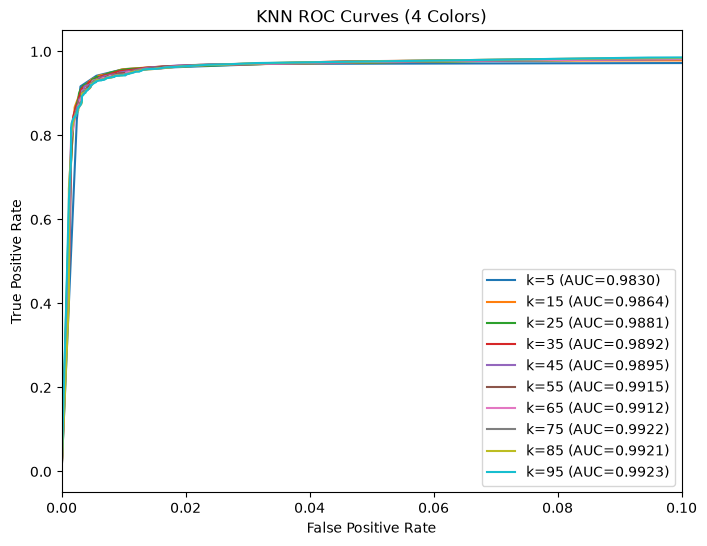

Best KNN n_neighbors: 95 (AUC = 0.9923)


In [30]:
plt.figure(figsize=(8, 6))
best_knn_auc, best_k = 0, 5
for k in range(5, 101, 10):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_col, y_train)
    qso_idx = np.where(knn.classes_ == 1)[0][0]
    y_prob = knn.predict_proba(X_test_col)[:, qso_idx]
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'k={k} (AUC={roc_auc:.4f})')
    if roc_auc > best_knn_auc:
        best_knn_auc, best_k = roc_auc, k

plt.xlim(0, 0.1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('KNN ROC Curves (4 Colors)')
plt.legend()
plt.show()
print(f"Best KNN n_neighbors: {best_k} (AUC = {best_knn_auc:.4f})")

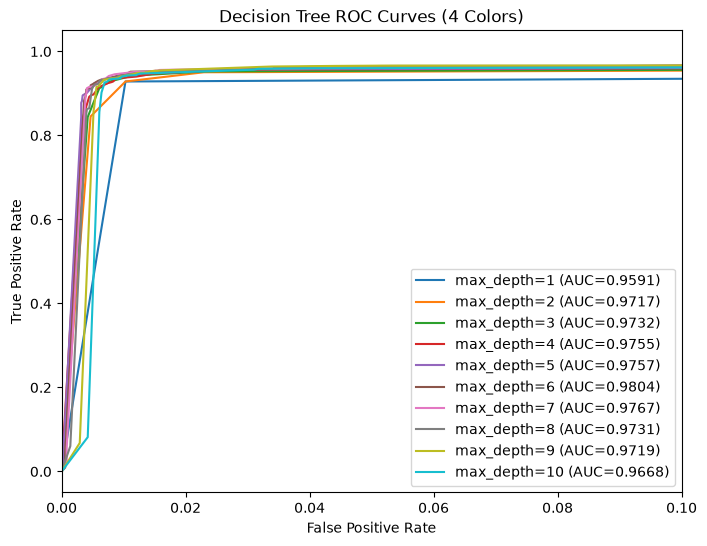

Best Decision Tree max_depth: 6 (AUC = 0.9804)


In [31]:
plt.figure(figsize=(8, 6))
best_dt_auc, best_depth = 0, 1
for depth in range(1, 11):
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train_col, y_train)
    qso_idx = np.where(dt.classes_ == 1)[0][0]
    y_prob = dt.predict_proba(X_test_col)[:, qso_idx]
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'max_depth={depth} (AUC={roc_auc:.4f})')
    if roc_auc > best_dt_auc:
        best_dt_auc, best_depth = roc_auc, depth

plt.xlim(0, 0.1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Decision Tree ROC Curves (4 Colors)')
plt.legend()
plt.show()
print(f"Best Decision Tree max_depth: {best_depth} (AUC = {best_dt_auc:.4f})")
